--- Model Performance on Test Set ---
R-squared (R²): 0.3163
Mean Absolute Error (MAE): 10.10 mmHg

--- Key Coefficients ---
BMI Coefficient: +0.8733 mmHg per kg/m²
AGE Coefficient: +0.5366 mmHg per year
Intercept: 61.69 mmHg



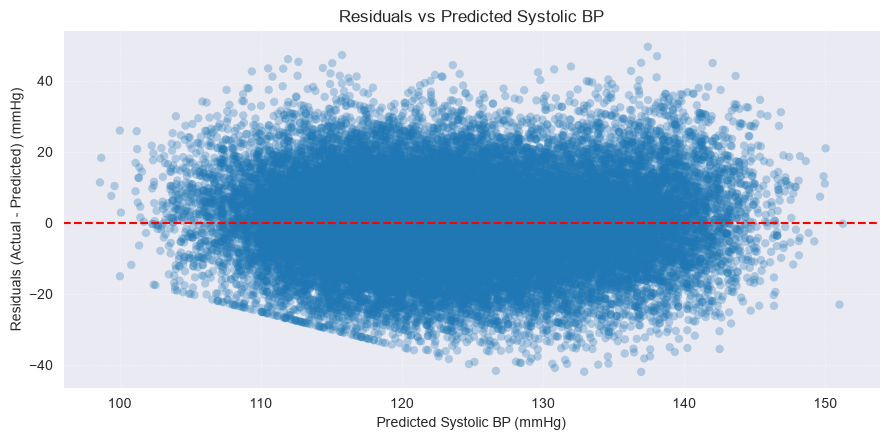

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Load data
try:
    df = pd.read_parquet("data/analysis_sample.parquet")
except Exception:
    df = pd.read_csv(r"C:\Users\ugochukwu.emenike\PycharmProjects\PythonProject\powerbi\analysis_sample.csv")

# 2. Fix NaN in target: Drop rows where the target (SYSTOLIC_BP) is missing
df = df.dropna(subset=['SYSTOLIC_BP']).copy()

# 3. Define target and permitted features
y = df['SYSTOLIC_BP']

leakage_cols = ['SYSTOLIC_BP', 'DIASTOLIC_BP', 'DIAGNOSED_HYPERTENSION', 'BP_CATEGORY', 'SAMPLE_ID']
if 'HIGH_BP_FLAG' in df.columns:
    leakage_cols.append('HIGH_BP_FLAG')

X = df.drop(columns=[col for col in leakage_cols if col in df.columns])

# 4. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Build Pipelines with Imputation (handles missing values in features seamlessly)
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numeric_features),
        ('cat', cat_pipeline, categorical_features)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 6. Fit model
model.fit(X_train, y_train)

# 7. Predictions & Metrics
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("--- Model Performance on Test Set ---")
print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f} mmHg\n")

# 8. Extract Feature Names and Coefficients
num_feature_names = numeric_features
cat_feature_names = model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_features).tolist()
all_feature_names = num_feature_names + cat_feature_names

coefs = pd.Series(model.named_steps['regressor'].coef_, index=all_feature_names)

print("--- Key Coefficients ---")
if 'BMI' in coefs:
    print(f"BMI Coefficient: {coefs['BMI']:+.4f} mmHg per kg/m²")
if 'AGE' in coefs:
    print(f"AGE Coefficient: {coefs['AGE']:+.4f} mmHg per year")
print(f"Intercept: {model.named_steps['regressor'].intercept_:.2f} mmHg\n")

# 9. Residuals Plot
residuals = y_test - y_pred

plt.figure(figsize=(9, 4.5))
plt.scatter(y_pred, residuals, alpha=0.3, edgecolors='none', color='#1f77b4')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title("Residuals vs Predicted Systolic BP")
plt.xlabel("Predicted Systolic BP (mmHg)")
plt.ylabel("Residuals (Actual - Predicted) (mmHg)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()